<h1>Stepping Probability</h1>
<h3>Binomial distribution for predicting walking distances</h3>
<p>G. Woehlke 2025ff (converted from Wolfram Mathematica, aided by A.I.)</p>

<h3>Introduction and initialization</h3>  

A large number of independent motor proteins that have the probability $p$ to step forwards in the interval $\Delta{t}$ will be distributed according to a binomial distribution, in <i>Mathematica</i> syntax <font face="courier">BinomialDistribution[n,p]</font>, in Python imported from the <i>SciPy</i> module. In this calculation example, the number of trials (or time slots) is $n = 40$, the stepping probability per time interval is $p = 0.05$. Then, this function returns the probability of finding motors that have travelled exactly two steps:  

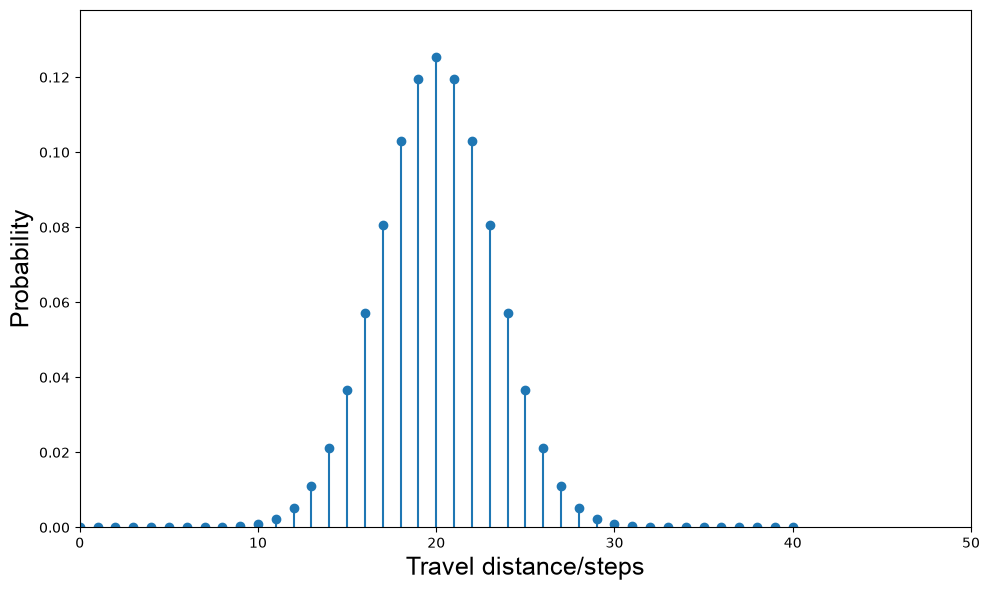

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n = 40
p = 0.5

k = np.arange(0, n + 1)
pmf = binom.pmf(k, n, p)

plt.figure(figsize=(10, 6))

# vertical lines (Mathematica-like discrete plot)
plt.vlines(k, 0, pmf)

# markers
plt.plot(k, pmf, 'o')

plt.xlabel("Travel distance/steps", fontsize=18, fontname="Arial")
plt.ylabel("Probability", fontsize=18, fontname="Arial")

plt.xlim(0, 50)
plt.ylim(0, pmf.max() * 1.1)

plt.grid(False)
plt.tight_layout()
plt.show()

<p>Steven Chu and coworkers use a parameter $\Phi = \frac{2 \mu}{s^2}$ that reflects the mean of the distribution, $\mu$, over the variance, $s^2$. Plotting the time dependence of $\Phi$ helps to test the presence of a random walk: If the  </p>
<ul>
    <li>Peng, C.S., Zhang, Y., Liu, Q., Marti, G.E., Huang, Y.-W.A., Südhof, T.C., Cui, B., Chu, S., 2025. <i>Nanometer-resolution tracking of single cargo reveals dynein motor mechanisms.</i> Nat Chem Biol 21, 648–656. <a href=https://doi.org/10.1038/s41589-024-01694-2>Link to DOI</a>. </li>
</ul>

In [2]:
import numpy as np

rng = np.random.default_rng(123)
data = rng.binomial(n=40, p=0.65, size=100)

In [3]:
phi = 2.0 * np.mean(data) / np.var(data, ddof=1)

In [4]:
print(phi)

6.534628855496552


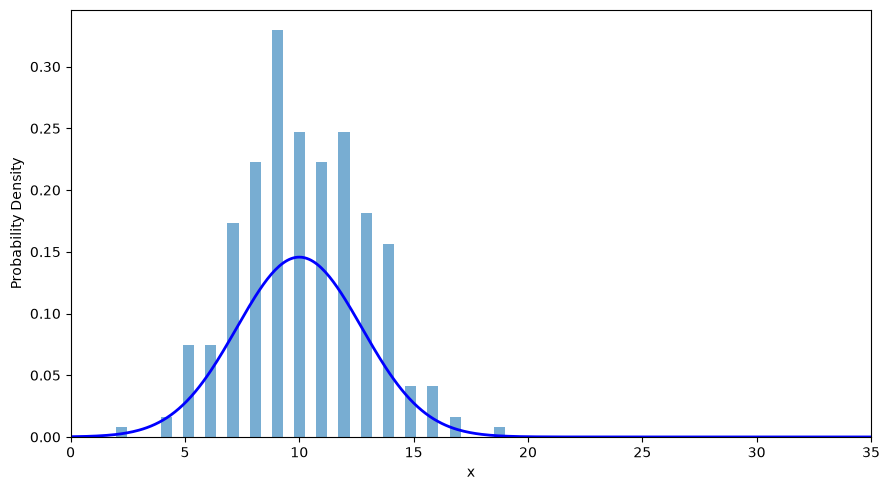

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

# parameters
n = 40
p = 0.25
size = 250

# sample data
data = np.random.binomial(n, p, size)

# normal approximation parameters
mu = n * p
sigma = np.sqrt(n * p * (1 - p))

# x-grid for normal curve
x = np.linspace(0, 35, 400)

plt.figure(figsize=(9,5))

# histogram with probability density normalization
plt.hist(data, bins=35, density=True, alpha=0.6)

# normal pdf overlay
plt.plot(x, norm.pdf(x, mu, sigma), linewidth=2, color="blue")

plt.xlim(0, 35)

plt.xlabel("x")
plt.ylabel("Probability Density")

plt.tight_layout()
plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display

def simulate(n=40, m=50, p=0.33, color="blue", lw=2, fs=14, grid=True, size=720):

    n = int(n)

    # generate binomial data
    data = np.random.binomial(n, p, m)

    # theoretical parameters
    mu = n * p
    sigma = np.sqrt(n * p * (1 - p))

    x = np.linspace(0, (n/p)*1.4, 400)

    fig = plt.figure(figsize=(size/100, size/140))

    # histogram
    plt.hist(data, bins=35, density=True, color="lightblue")

    # normal approximation
    plt.plot(x, norm.pdf(x, mu, sigma), color=color, linewidth=lw)

    plt.xlabel("number of steps", fontsize=fs)
    plt.ylabel("fraction of motors at #steps", fontsize=fs)

    if grid:
        plt.grid(True)

    # info panel
    text = (
        f"Number of motors m = {m}\n"
        f"Number of time slots n = {n}\n"
        f"Stepping probability p = {p:.2f}\n"
        f"Mean (theory): {mu:.2f}\n"
        f"Variance (theory): {n*(1-p)*p:.2f}\n"
        f"Phi = ⬿2 mean/var: {mu/(n*(1-p)*p):.2f}"
    )

    plt.text(0.72,0.75,text,
             transform=plt.gca().transAxes,
             fontsize=fs,
             bbox=dict(facecolor="white"))

    plt.show()


widgets.interact(
    simulate,
    n=widgets.IntSlider(value=40,min=5,max=100),
    m=widgets.IntSlider(value=50,min=25,max=250),
    p=widgets.FloatSlider(value=0.33,min=0.1,max=0.99,step=0.01),
    color=["orange","red","yellow","gray","blue","green"],
    lw=widgets.FloatSlider(value=2,min=1,max=5),
    fs=[9,12,14,18,24],
    grid=[True,False],
    size=[450,650,720,900,1080]
)

interactive(children=(IntSlider(value=40, description='n', min=5), IntSlider(value=50, description='m', max=25…

<function __main__.simulate(n=40, m=50, p=0.33, color='blue', lw=2, fs=14, grid=True, size=720)>

Sample _Mathematica_ outcome: <img src="./20_SteppingProbability.svg" />